<a href="https://colab.research.google.com/github/Gizeh-Gutierrez/Maestria_programacion/blob/main/Semana13_2_271752.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Alumno: **Gizeh Gutierrez**

Matricula: **271752**

In [36]:

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix


df = pd.read_csv('/content/drive/MyDrive/ClassFiles/compustat.csv')

# Mostrar dimensiones
print("Dimensiones:", df.shape)

# Visualizar primeras filas
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensiones: (13657, 22)


,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


In [37]:
# ignorar la primera columna
X = df.iloc[:, 1:-1]

# Variable objetivo
y = df.iloc[:, -1]

print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (13657, 20)
Variable objetivo: (13657,)


In [38]:
print("Atributos predictivos:")
print(X.columns)

print("\nEtiqueta de clase:")
print(y.name)

Atributos predictivos:
Index(['at0', 'at1', 'at2', 'at3', 'at4', 'at5', 'at6', 'at7', 'at8', 'at9',
       'at10', 'at11', 'at12', 'at13', 'at14', 'at15', 'at16', 'at17', 'at18',
       'at19'],
      dtype='object')

Etiqueta de clase:
label


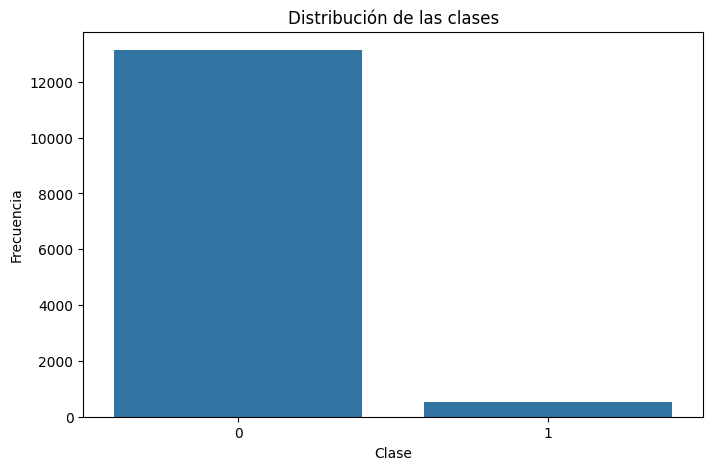

       Frecuencia  Porcentaje (%)
label                            
0           13137           96.19
1             520            3.81


In [39]:
# Distribución de clases
plt.figure(figsize=(8,5))
sns.countplot(x=y)
plt.title('Distribución de las clases')
plt.xlabel('Clase')
plt.ylabel('Frecuencia')
plt.show()

conteo = y.value_counts()
porcentaje = y.value_counts(normalize=True) * 100

print(pd.DataFrame({
    'Frecuencia': conteo,
    'Porcentaje (%)': porcentaje.round(2)
}))

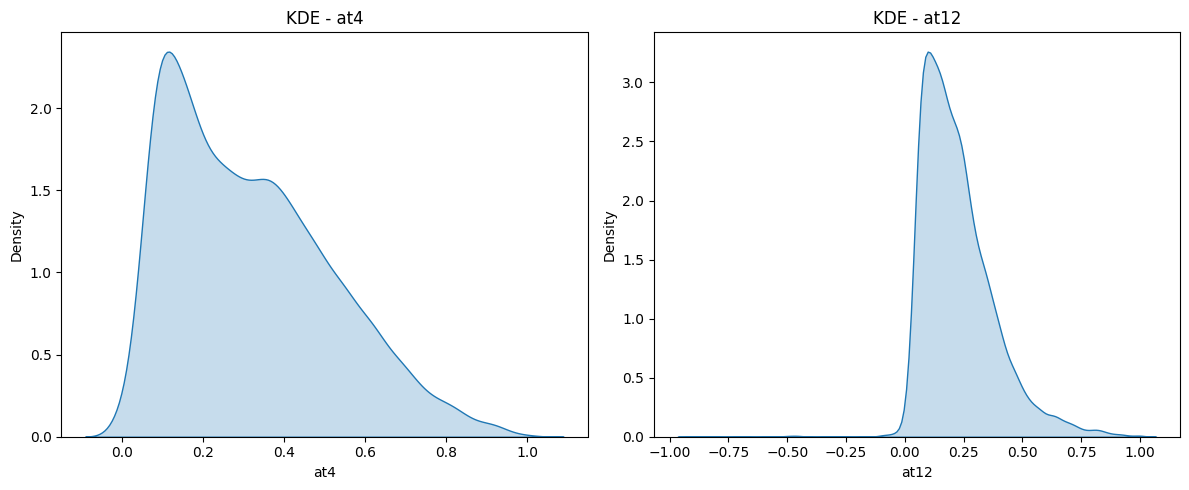

Atributo 5: at4
Atributo 13: at12


In [40]:
# Atributo 5 y atributo 13
atributo_5 = X.columns[4]
atributo_13 = X.columns[12]

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.kdeplot(data=X, x=atributo_5, fill=True)
plt.title(f'KDE - {atributo_5}')

plt.subplot(1,2,2)
sns.kdeplot(data=X, x=atributo_13, fill=True)
plt.title(f'KDE - {atributo_13}')

plt.tight_layout()
plt.show()

print("Atributo 5:", atributo_5)
print("Atributo 13:", atributo_13)

In [41]:
porcentaje = y.value_counts(normalize=True) * 100
print(porcentaje)

label
0    96.192429
1     3.807571
Name: proportion, dtype: float64


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# baseline
baseline_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# Entrenamiento
baseline_model.fit(X_train, y_train)

# Predicciones
y_pred = baseline_model.predict(X_test)

# Evaluación
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Accuracy: 0.962298682284041

Matriz de confusión:
[[2628    0]
 [ 103    1]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      2628
           1       1.00      0.01      0.02       104

    accuracy                           0.96      2732
   macro avg       0.98      0.50      0.50      2732
weighted avg       0.96      0.96      0.94      2732



METODO 1 SMOTEENN

In [43]:
!pip install imbalanced-learn

In [44]:
from imblearn.combine import SMOTEENN

#  SMOTEENN
smoteenn = SMOTEENN(random_state=42)

X_train_smoteenn, y_train_smoteenn = smoteenn.fit_resample(X_train, y_train)

# Nueva distribución
print("Distribución original:")
print(y_train.value_counts())

print("\nDistribución después de SMOTEENN:")
print(pd.Series(y_train_smoteenn).value_counts())

Distribución original:
label
0    10509
1      416
Name: count, dtype: int64

Distribución después de SMOTEENN:
label
1    10434
0     9395
Name: count, dtype: int64


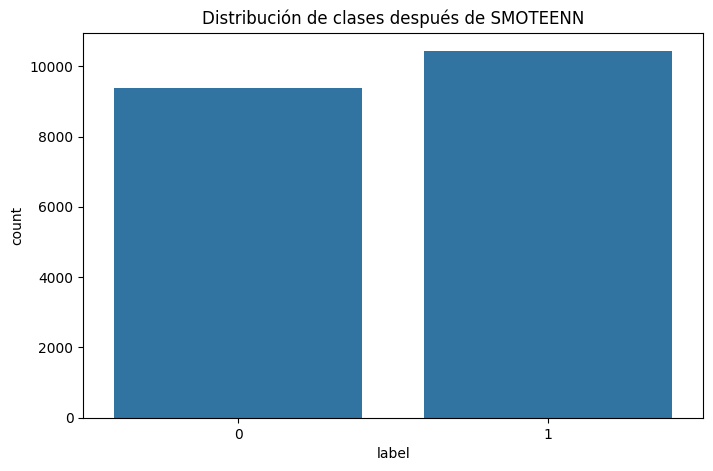

In [45]:


plt.figure(figsize=(8,5))
sns.countplot(x=y_train_smoteenn)
plt.title('Distribución de clases después de SMOTEENN')
plt.show()

In [46]:
svm_smoteenn = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

svm_smoteenn.fit(X_train_smoteenn, y_train_smoteenn)

y_pred_smoteenn = svm_smoteenn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_smoteenn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smoteenn))

Accuracy: 0.8089311859443631

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.81      0.89      2628
           1       0.15      0.86      0.25       104

    accuracy                           0.81      2732
   macro avg       0.57      0.83      0.57      2732
weighted avg       0.96      0.81      0.87      2732



METODO 2  ONE-SIDED SELECTION

In [47]:
from imblearn.under_sampling import OneSidedSelection

oss = OneSidedSelection(random_state=42)

X_train_oss, y_train_oss = oss.fit_resample(X_train, y_train)

print("Distribución original:")
print(y_train.value_counts())

print("\nDistribución después de OSS:")
print(pd.Series(y_train_oss).value_counts())

Distribución original:
label
0    10509
1      416
Name: count, dtype: int64

Distribución después de OSS:
label
0    10222
1      416
Name: count, dtype: int64


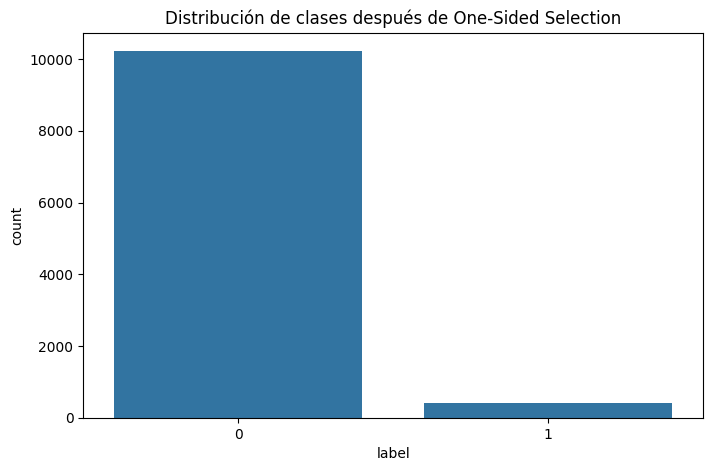

In [48]:
plt.figure(figsize=(8,5))
sns.countplot(x=y_train_oss)
plt.title('Distribución de clases después de One-Sided Selection')
plt.show()

In [49]:
svm_oss = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

svm_oss.fit(X_train_oss, y_train_oss)

y_pred_oss = svm_oss.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_oss))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_oss))

Accuracy: 0.962298682284041

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      2628
           1       1.00      0.01      0.02       104

    accuracy                           0.96      2732
   macro avg       0.98      0.50      0.50      2732
weighted avg       0.96      0.96      0.94      2732



In [50]:
from sklearn.metrics import f1_score, recall_score

resultados = pd.DataFrame({
    'Modelo': ['Baseline', 'SMOTEENN', 'OSS'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_smoteenn),
        accuracy_score(y_test, y_pred_oss)
    ],
    'F1 Macro': [
        f1_score(y_test, y_pred, average='macro'),
        f1_score(y_test, y_pred_smoteenn, average='macro'),
        f1_score(y_test, y_pred_oss, average='macro')
    ],
    'Recall Macro': [
        recall_score(y_test, y_pred, average='macro'),
        recall_score(y_test, y_pred_smoteenn, average='macro'),
        recall_score(y_test, y_pred_oss, average='macro')
    ]
})

print(resultados)

     Modelo  Accuracy  F1 Macro  Recall Macro
0  Baseline  0.962299  0.499914      0.504808
1  SMOTEENN  0.808931  0.572357      0.831423
2       OSS  0.962299  0.499914      0.504808


In [51]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [52]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale'
    ))
])

In [53]:
metricas = {
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',
    'recall_macro': 'recall_macro',
    'precision_macro': 'precision_macro'
}

resultados = cross_validate(
    pipeline,
    X,
    y,
    cv=cv,
    scoring=metricas,
    n_jobs=-1
)

for metrica in metricas:
    print(
        f"{metrica}: "
        f"{resultados['test_' + metrica].mean():.4f} "
        f"+/- {resultados['test_' + metrica].std():.4f}"
    )

accuracy: 0.9622 +/- 0.0003
f1_macro: 0.4980 +/- 0.0071
recall_macro: 0.5038 +/- 0.0036
precision_macro: 0.7811 +/- 0.2451


In [54]:
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTEENN

pipeline_smoteenn = Pipeline([
    ('smoteenn', SMOTEENN(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

resultados_smoteenn = cross_validate(
    pipeline_smoteenn,
    X,
    y,
    cv=cv,
    scoring=metricas,
    n_jobs=-1
)

print("F1 Macro:",
      resultados_smoteenn['test_f1_macro'].mean())

F1 Macro: 0.5690755939530022


In [55]:
from imblearn.under_sampling import OneSidedSelection

pipeline_oss = Pipeline([
    ('oss', OneSidedSelection(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

resultados_oss = cross_validate(
    pipeline_oss,
    X,
    y,
    cv=cv,
    scoring=metricas,
    n_jobs=-1
)

print("F1 Macro:",
      resultados_oss['test_f1_macro'].mean())

F1 Macro: 0.4979526695486304


In [56]:
comparacion = pd.DataFrame({
    'Modelo': ['Baseline', 'SMOTEENN', 'OSS'],
    'Accuracy': [
        resultados['test_accuracy'].mean(),
        resultados_smoteenn['test_accuracy'].mean(),
        resultados_oss['test_accuracy'].mean()
    ],
    'Precision Macro': [
        resultados['test_precision_macro'].mean(),
        resultados_smoteenn['test_precision_macro'].mean(),
        resultados_oss['test_precision_macro'].mean()
    ],
    'Recall Macro': [
        resultados['test_recall_macro'].mean(),
        resultados_smoteenn['test_recall_macro'].mean(),
        resultados_oss['test_recall_macro'].mean()
    ],
    'F1 Macro': [
        resultados['test_f1_macro'].mean(),
        resultados_smoteenn['test_f1_macro'].mean(),
        resultados_oss['test_f1_macro'].mean()
    ]
})

comparacion.round(4)

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Baseline,0.9622,0.7811,0.5038,0.4980
1,SMOTEENN,0.8120,0.5677,0.8081,0.5691
2,OSS,0.9622,0.7811,0.5038,0.4980


Los resultados muestran que existe un problema de desbalance de clases en el conjunto de datos.El modelo Baseline alcanzó la mayor Accuracy 96.22%, pero su bajo Recall Macro 0.5038 y F1 Macro 0.4980 lo que indica un desempeño deficiente de las clases minoritarias. SMOTEENN logró mejorar  la capacidad de detección de todas las clases, elevando el Recall Macro  0.8081 y el F1 Macro 0.5691. SMOTEENN puede considerarse la mejor alternativa, ya que proporciona un modelo más equilibrado y robusto, aun cuando la Accuracy global disminuye. OSS no mostró mejoras respecto al modelo Baseline.

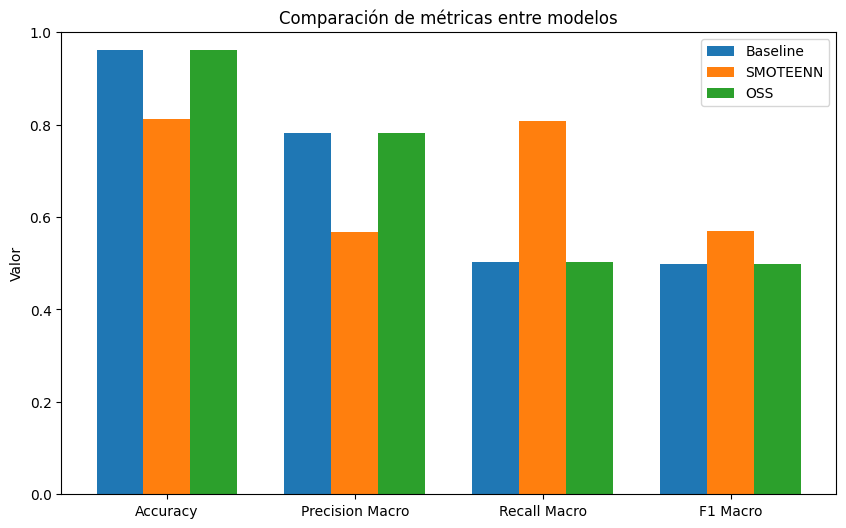

In [57]:

import numpy as np

resultados = pd.DataFrame({
    'Modelo': ['Baseline', 'SMOTEENN', 'OSS'],
    'Accuracy': [0.9622, 0.8120, 0.9622],
    'Precision Macro': [0.7811, 0.5677, 0.7811],
    'Recall Macro': [0.5038, 0.8081, 0.5038],
    'F1 Macro': [0.4980, 0.5691, 0.4980]
})

metricas = ['Accuracy', 'Precision Macro', 'Recall Macro', 'F1 Macro']

x = np.arange(len(metricas))
width = 0.25

plt.figure(figsize=(10,6))

plt.bar(x - width, resultados.iloc[0,1:], width, label='Baseline')
plt.bar(x, resultados.iloc[1,1:], width, label='SMOTEENN')
plt.bar(x + width, resultados.iloc[2,1:], width, label='OSS')

plt.xticks(x, metricas)
plt.ylabel('Valor')
plt.title('Comparación de métricas entre modelos')
plt.ylim(0,1)
plt.legend()

plt.show()


El modelo Baseline obtuvo la mayor Accuracy 96.22%, pero presentó valores bajos de Recall Macro y F1 Macro.
SMOTEENN redujo la Accuracy a 81.20%, pero mejoró considerablemente el Recall Macro de 0.5038 a 0.8081 y el F1 Macro de 0.4980 a 0.5691.
OSS produjo exactamente los mismos resultados que el modelo Baseline.

La Accuracy por sí sola resulta insuficiente cuando existe desbalance de clases. En este caso, el modelo Baseline y el modelo OSS alcanzan una Accuracy muy alta 96.22%, lo que podría llevar a concluir  que son los mejores modelos cuando no es asi.

Al analizar las métricas macro podemos ver que:

El Recall Macro del Baseline es únicamente 0.5038.
El F1 Macro del Baseline es 0.4980.

Lo que indica que el modelo tiene dificultades para identificar correctamente las clases minoritarias.

SMOTEENN reduce la Accuracy global, pero aumenta significativamente el Recall Macro  0.8081 y mejora el F1 Macro a 0.5691. Esto demuestra que el modelo reconoce mejor todas las clases y no solamente la clase mayoritaria.

 SMOTEENN permitió obtener un modelo más equilibrado, incrementando significativamente el Recall Macro y el F1 Macro, métricas que reflejan mejor la capacidad del clasificador para reconocer todas las clases. Por ello, SMOTEENN fue el método más efectivo y de mejor desempeño.